In [1]:
import pandas as pd
import numpy as np

In [24]:
df = pd.read_csv('datasets/shot_events.csv')
df.head()

,league,season,game,team,player,league_id,season_id,game_id,date,shot_id,...,player_id,assist_player_id,assist_player,xg,location_x,location_y,minute,body_part,situation,result
0,ENG-Premier League,2223,2022-08-05 Crystal Palace-Arsenal,Arsenal,Bukayo Saka,1,2022,18202,2022-08-05 19:00:00,479033,...,7322,539138.0,Ben White,0.078887,0.960,0.328,69,Right Foot,Open Play,Missed Shot
1,ENG-Premier League,2223,2022-08-05 Crystal Palace-Arsenal,Arsenal,Bukayo Saka,1,2022,18202,2022-08-05 19:00:00,479038,...,7322,539142.0,Thomas Partey,0.057627,0.950,0.277,84,Right Foot,Open Play,Missed Shot
2,ENG-Premier League,2223,2022-08-05 Crystal Palace-Arsenal,Arsenal,Bukayo Saka,1,2022,18202,2022-08-05 19:00:00,479040,...,7322,539149.0,Eddie Nketiah,0.096064,0.929,0.330,86,Right Foot,Open Play,Blocked Shot
3,ENG-Premier League,2223,2022-08-05 Crystal Palace-Arsenal,Arsenal,Gabriel Jesus,1,2022,18202,2022-08-05 19:00:00,479020,...,5543,NaN,NaN,0.181834,0.883,0.507,3,Right Foot,Open Play,Blocked Shot
4,ENG-Premier League,2223,2022-08-05 Crystal Palace-Arsenal,Arsenal,Gabriel Martinelli,1,2022,18202,2022-08-05 19:00:00,479021,...,7752,NaN,NaN,0.340446,0.935,0.612,3,Left Foot,Open Play,Missed Shot


#### 1. Calafiori impact in attack as a left-back

In [5]:
cala = df[df['assist_player'] == 'Riccardo Calafiori']
cala

,league,season,game,team,player,league_id,season_id,game_id,date,shot_id,...,player_id,assist_player_id,assist_player,xg,location_x,location_y,minute,body_part,situation,result
21489,ENG-Premier League,2425,2024-09-28 Arsenal-Leicester,Arsenal,Declan Rice,1,2024,26655,2024-09-28 14:00:00,594130,...,5553,677837.0,Riccardo Calafiori,0.021124,0.775,0.701,72,Right Foot,Open Play,Saved Shot
21512,ENG-Premier League,2425,2024-09-28 Arsenal-Leicester,Arsenal,Leandro Trossard,1,2024,26655,2024-09-28 14:00:00,594126,...,7698,677837.0,Riccardo Calafiori,0.059793,0.872,0.531,66,Left Foot,From Corner,Blocked Shot
24490,ENG-Premier League,2425,2024-12-21 Crystal Palace-Arsenal,Arsenal,Declan Rice,1,2024,26765,2024-12-21 17:30:00,608533,...,5553,695507.0,Riccardo Calafiori,0.048660,0.841,0.706,83,Right Foot,Open Play,Goal
25194,ENG-Premier League,2425,2025-01-01 Brentford-Arsenal,Arsenal,Mikel Merino,1,2024,26783,2025-01-01 17:30:00,609799,...,5304,697030.0,Riccardo Calafiori,0.122242,0.870,0.526,56,Right Foot,Open Play,Missed Shot
26836,ENG-Premier League,2425,2025-02-22 Arsenal-West Ham,Arsenal,Declan Rice,1,2024,26853,2025-02-22 15:00:00,618407,...,5553,707764.0,Riccardo Calafiori,0.043426,0.910,0.723,38,Right Foot,From Corner,Blocked Shot
27229,ENG-Premier League,2425,2025-02-26 Nottingham Forest-Arsenal,Arsenal,Ethan Nwaneri,1,2024,26864,2025-02-26 19:30:00,619555,...,11132,709161.0,Riccardo Calafiori,0.110368,0.968,0.663,40,Left Foot,Open Play,Blocked Shot
30327,ENG-Premier League,2526,2025-08-23 Arsenal-Leeds,Arsenal,Jurriën Timber,1,2025,28793,2025-08-23 16:30:00,638958,...,11707,733389.0,Riccardo Calafiori,0.169588,0.969,0.508,55,Right Foot,From Corner,Goal
30338,ENG-Premier League,2526,2025-08-23 Arsenal-Leeds,Arsenal,Viktor Gyokeres,1,2025,28793,2025-08-23 16:30:00,638953,...,7254,733389.0,Riccardo Calafiori,0.178430,0.899,0.605,47,Right Foot,Open Play,Goal
30740,ENG-Premier League,2526,2025-09-13 Arsenal-Nottingham Forest,Arsenal,Gabriel,1,2025,28808,2025-09-13 11:30:00,641380,...,5613,736529.0,Riccardo Calafiori,0.018702,0.803,0.748,35,Left Foot,Open Play,Blocked Shot
31413,ENG-Premier League,2526,2025-09-28 Newcastle United-Arsenal,Arsenal,Viktor Gyokeres,1,2025,28836,2025-09-28 15:30:00,645469,...,7254,741582.0,Riccardo Calafiori,0.018635,0.861,0.581,50,NaN,Open Play,Missed Shot


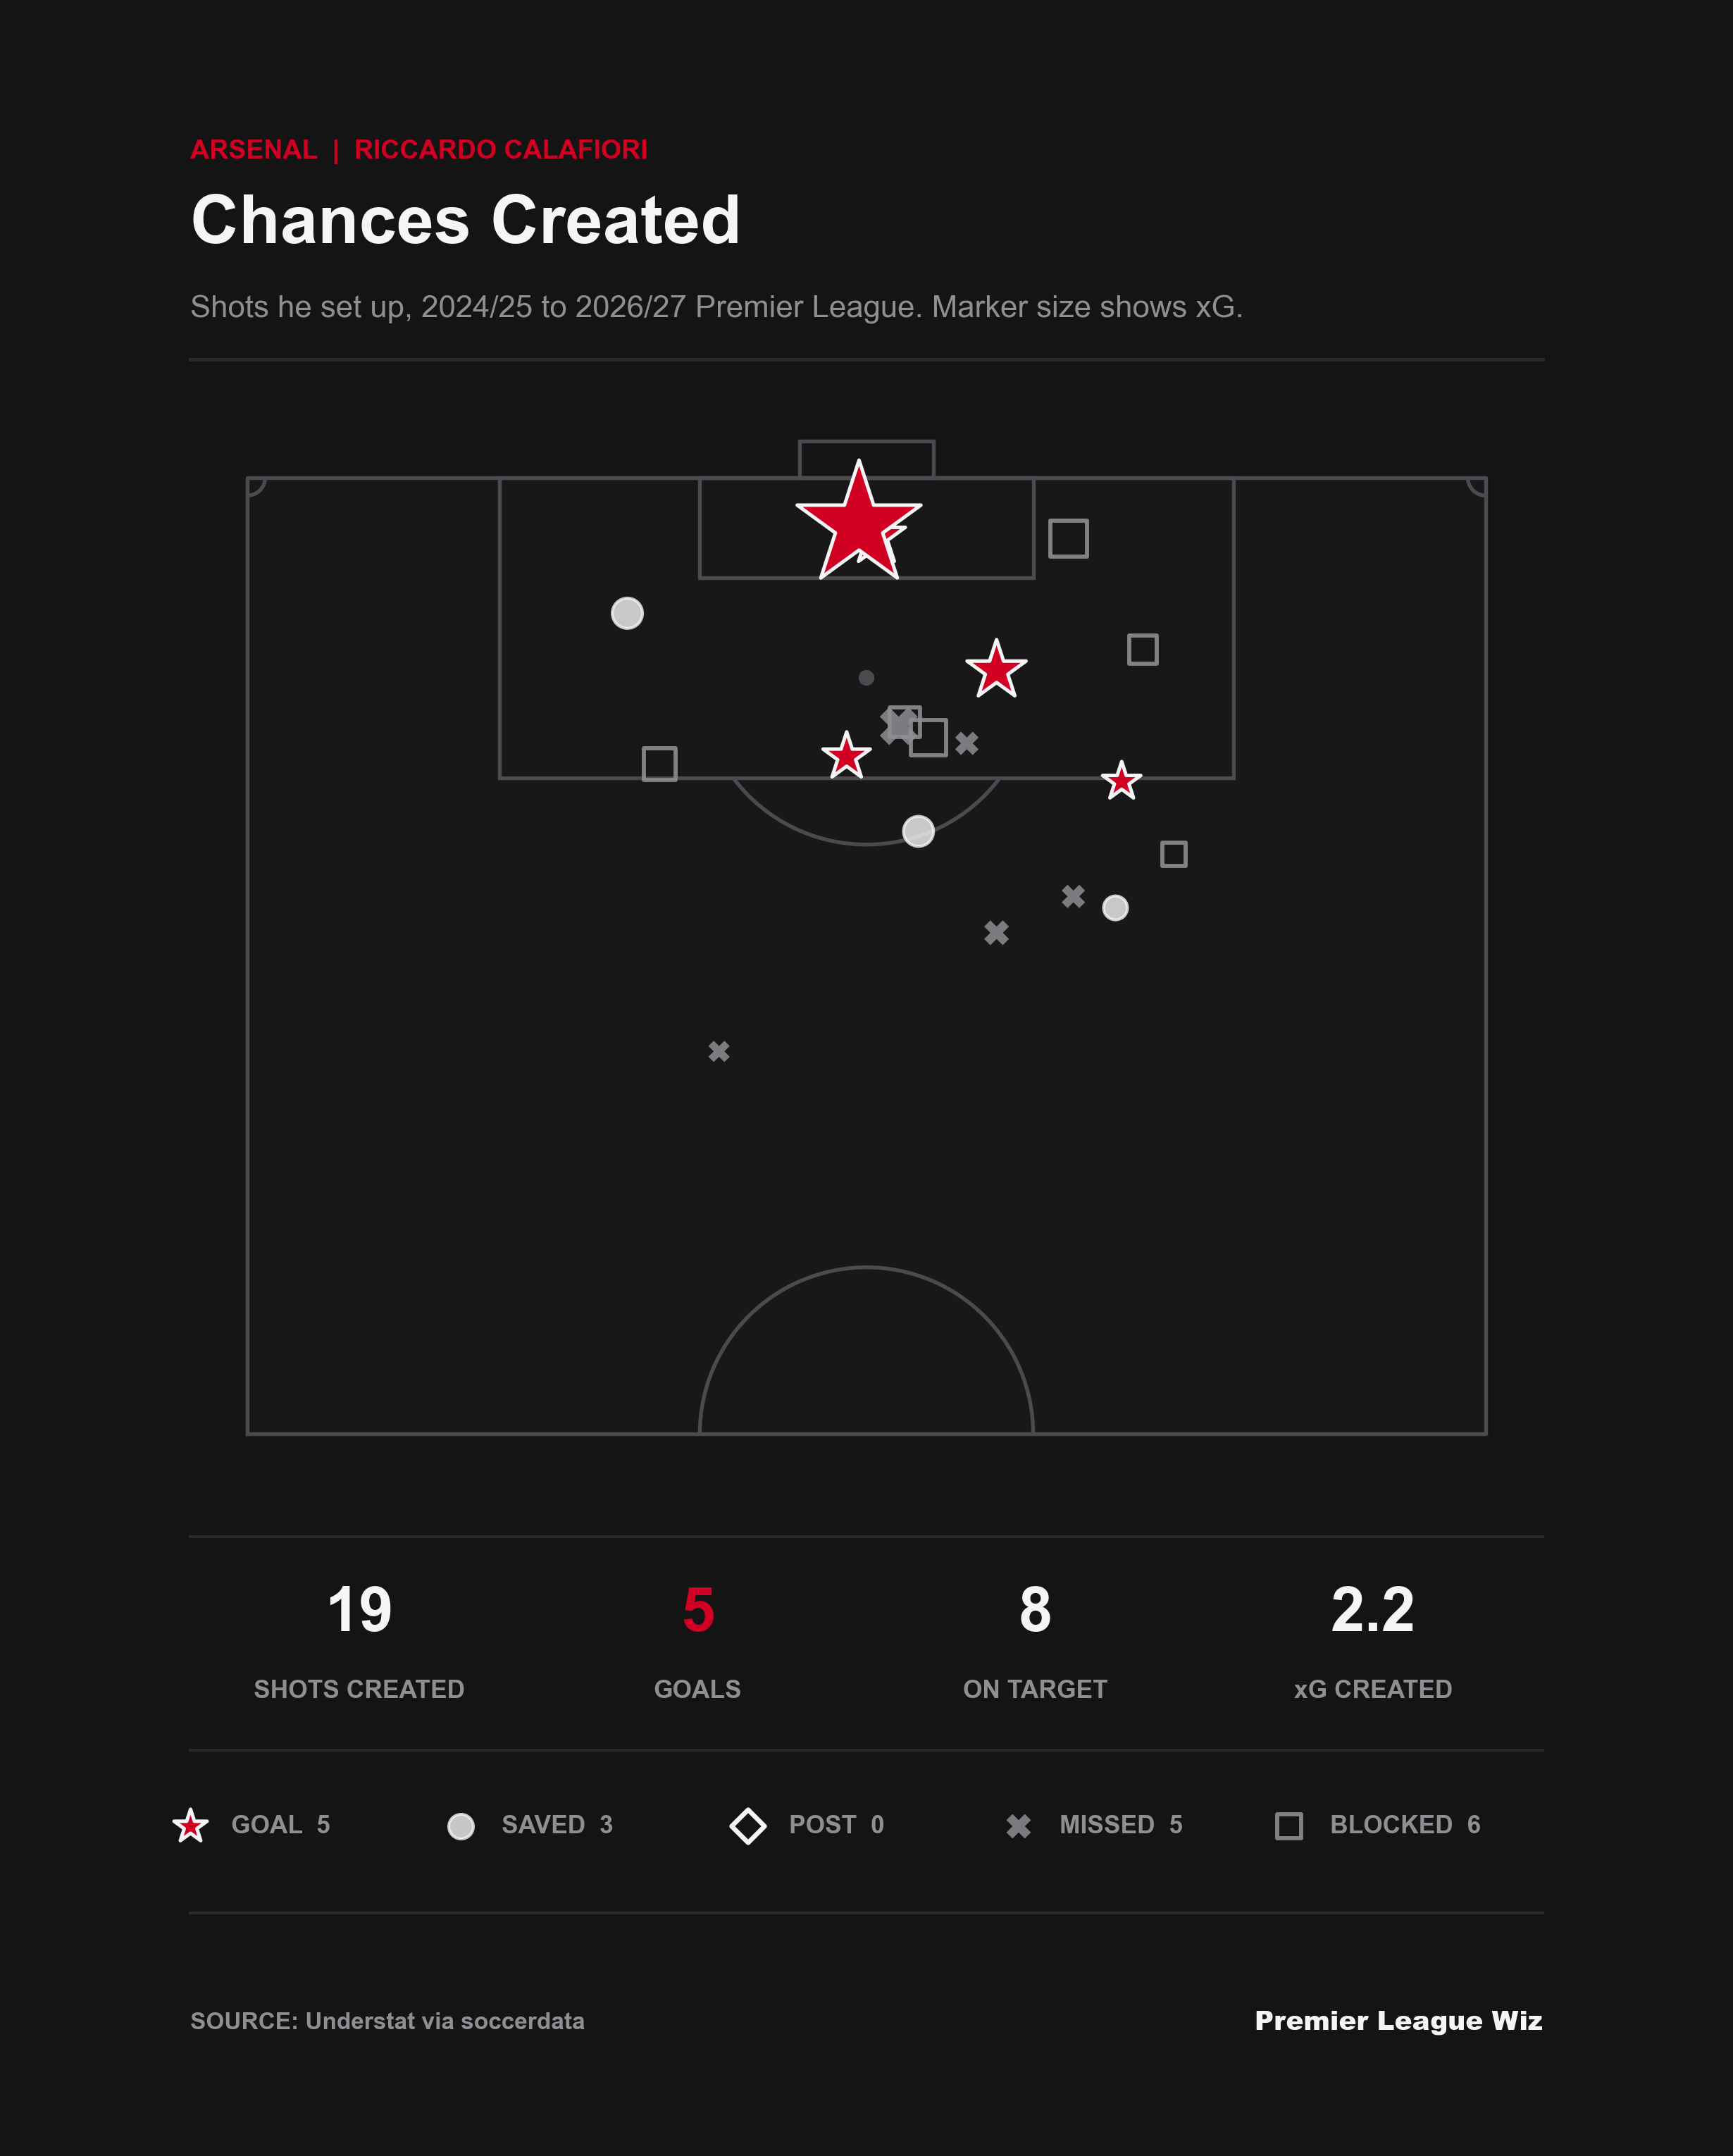

In [8]:
import re

import matplotlib.pyplot as plt

from matplotlib.patches import Arc, Circle, Rectangle

# ------------------------------------------------------------------
# THEME (same tokens as the standings table and prediction bars)
# ------------------------------------------------------------------
THEME = {
    "bg": "#141414",          # Matte charcoal
    "border": "#2A2A2E",      # Subtle divider line
    "accent": "#D10022",      # Signature crimson
    "white": "#F5F5F5",
    "muted": "#8E8E93",
    "zebra": "#1A1A1A",
    "pitch_fill": "#181818",  # Barely-there lift for the pitch
    "pitch_line": "#4A4A50",  # Pitch markings
}

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = [
    "Inter", "Graphik", "Helvetica Neue", "Arial", "DejaVu Sans"
]

# ------------------------------------------------------------------
# DATA CONFIG  (Understat via soccerdata: location_x/y are 0-1, x = towards goal)
# ------------------------------------------------------------------
X_COL, Y_COL = "location_x", "location_y"
RESULT_COL, XG_COL = "result", "xg"
FLIP_Y = False            # set True if left/right look mirrored

PITCH_L, PITCH_W = 105.0, 68.0

# Understat results -> display category (matching ignores case, spaces, punctuation)
RESULT_MAP = {
    "goal": "Goal",
    "savedshot": "Saved",
    "shotonpost": "Post",
    "missedshots": "Missed",
    "missedshot": "Missed",
    "blockedshot": "Blocked",
}

# Marker style per category (drawn in this order, goals last = on top)
STYLE = {
    "Blocked": dict(marker="s", fc="none",          ec=THEME["muted"],  lw=1.4, alpha=0.9,  z=3, k=1.0),
    "Missed":  dict(marker="X", fc=THEME["muted"],  ec="none",          lw=0.0, alpha=0.85, z=3, k=1.0),
    "Post":    dict(marker="D", fc="none",          ec=THEME["white"],  lw=1.6, alpha=1.0,  z=4, k=0.9),
    "Saved":   dict(marker="o", fc=THEME["white"],  ec=THEME["white"],  lw=1.0, alpha=0.8,  z=4, k=1.0),
    "Goal":    dict(marker="*", fc=THEME["accent"], ec=THEME["white"],  lw=1.2, alpha=1.0,  z=6, k=2.0),
}
LEGEND_ORDER = ["Goal", "Saved", "Post", "Missed", "Blocked"]


# ------------------------------------------------------------------
# PREP
# ------------------------------------------------------------------
def prepare_shots(df):
    """Add pitch coordinates (metres, goal at the top) and a result category."""
    for c in (X_COL, Y_COL, RESULT_COL):
        if c not in df.columns:
            raise KeyError(
                f"Column '{c}' not found. Available columns: {list(df.columns)}"
            )

    out = df.copy()
    x = out[X_COL].astype(float)
    y = out[Y_COL].astype(float)

    # Auto-detect scale: 0-1, 0-100, or already metres
    top = max(x.max(), y.max())
    if top <= 1.5:
        x, y = x * PITCH_L, y * PITCH_W
    elif top <= 100.5:
        x, y = x / 100 * PITCH_L, y / 100 * PITCH_W

    # Vertical half pitch: attack runs up the page, attacker's left = left of page
    out["px"] = (PITCH_W - y) if FLIP_Y else y
    out["py"] = x

    key = out[RESULT_COL].astype(str).str.lower().str.replace(r"[^a-z]", "", regex=True)
    out["category"] = key.map(RESULT_MAP)

    dropped = out[out["category"].isna()]
    if len(dropped):
        print("Skipped results not mapped:", dropped[RESULT_COL].unique().tolist())
    return out.dropna(subset=["category", "px", "py"])


def season_label(df):
    if "season" not in df.columns or df["season"].isna().all():
        return ""
    labels = []
    for s in sorted(df["season"].astype(str).unique()):
        labels.append(f"20{s[:2]}/{s[2:]}" if len(s) == 4 and s.isdigit() else s)
    return " to ".join([labels[0], labels[-1]]) if len(labels) > 1 else labels[0]


# ------------------------------------------------------------------
# PITCH
# ------------------------------------------------------------------
def draw_half_pitch(ax):
    t = THEME
    kw = dict(color=t["pitch_line"], lw=1.3, zorder=1)
    cx = PITCH_W / 2

    ax.add_patch(Rectangle((0, PITCH_L / 2), PITCH_W, PITCH_L / 2,
                           fc=t["pitch_fill"], ec="none", zorder=0))

    # Outline + halfway line
    ax.plot([0, PITCH_W, PITCH_W, 0, 0],
            [PITCH_L / 2, PITCH_L / 2, PITCH_L, PITCH_L, PITCH_L / 2], **kw)

    # Penalty area, six-yard box, goal frame
    ax.add_patch(Rectangle((cx - 20.16, PITCH_L - 16.5), 40.32, 16.5,
                           fill=False, ec=kw["color"], lw=kw["lw"], zorder=1))
    ax.add_patch(Rectangle((cx - 9.16, PITCH_L - 5.5), 18.32, 5.5,
                           fill=False, ec=kw["color"], lw=kw["lw"], zorder=1))
    ax.add_patch(Rectangle((cx - 3.66, PITCH_L), 7.32, 2.0,
                           fill=False, ec=kw["color"], lw=kw["lw"], zorder=1))

    # Penalty spot, penalty arc (the "D"), centre circle, corner arcs
    ax.add_patch(Circle((cx, PITCH_L - 11), 0.35, color=kw["color"], zorder=1))
    ax.add_patch(Arc((cx, PITCH_L - 11), 18.3, 18.3, theta1=216.87, theta2=323.13,
                     ec=kw["color"], lw=kw["lw"], zorder=1))
    ax.add_patch(Arc((cx, PITCH_L / 2), 18.3, 18.3, theta1=0, theta2=180,
                     ec=kw["color"], lw=kw["lw"], zorder=1))
    ax.add_patch(Arc((0, PITCH_L), 2, 2, theta1=270, theta2=360,
                     ec=kw["color"], lw=kw["lw"], zorder=1))
    ax.add_patch(Arc((PITCH_W, PITCH_L), 2, 2, theta1=180, theta2=270,
                     ec=kw["color"], lw=kw["lw"], zorder=1))

    ax.set_xlim(-2, PITCH_W + 2)
    ax.set_ylim(PITCH_L / 2 - 2.5, PITCH_L + 3)
    ax.set_aspect("equal")
    ax.axis("off")


# ------------------------------------------------------------------
# CHART
# ------------------------------------------------------------------
def plot_shot_map(
    shots,
    player="Riccardo Calafiori",
    team=None,
    league_label="Premier League",
    title="Chances Created",
    source="SOURCE: Understat via soccerdata",
    brand="Premier League Wiz",
    outfile="the_athletic_shot_map.png",
):
    t = THEME
    d = prepare_shots(shots)
    team = team or (d["team"].mode().iat[0] if "team" in d.columns and len(d) else "")
    has_xg = XG_COL in d.columns
    xg = d[XG_COL].astype(float) if has_xg else pd.Series(0.12, index=d.index)

    counts = d["category"].value_counts().to_dict()
    n_shots = len(d)
    n_goals = counts.get("Goal", 0)
    n_target = n_goals + counts.get("Saved", 0)
    xg_total = float(xg.sum()) if has_xg else None

    # 4:5 vertical canvas; `ax` carries the editorial chrome in 0-100 space
    fig = plt.figure(figsize=(8, 10), dpi=300)
    fig.patch.set_facecolor(t["bg"])
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_facecolor(t["bg"])
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.axis("off")

    # Header deck
    who = player.upper() if not team else f"{team.upper()}  |  {player.upper()}"
    sub_season = season_label(d)
    fig.text(0.10, 0.935, who, fontsize=9, fontweight="bold",
             color=t["accent"], ha="left")
    fig.text(0.10, 0.895, title, fontsize=23, fontweight="heavy",
             color=t["white"], ha="left")
    sub = f"Shots he set up, {sub_season} {league_label}. Marker size shows xG."
    fig.text(0.10, 0.860, sub.replace("  ", " "), fontsize=10.5,
             color=t["muted"], ha="left")
    ax.plot([10, 90], [84, 84], color=t["border"], lw=1.2)

    # Pitch
    pax = fig.add_axes([0.10, 0.31, 0.80, 0.50])
    pax.set_facecolor("none")
    draw_half_pitch(pax)

    for cat in ["Blocked", "Missed", "Post", "Saved", "Goal"]:
        sub_df = d[d["category"] == cat]
        if sub_df.empty:
            continue
        s = STYLE[cat]
        size = (45 + 1000 * xg.loc[sub_df.index].values) * s["k"]
        pax.scatter(sub_df["px"], sub_df["py"], s=size, marker=s["marker"],
                    facecolors=s["fc"], edgecolors=s["ec"], linewidths=s["lw"],
                    alpha=s["alpha"], zorder=s["z"])

    # Stat strip
    ax.plot([10, 90], [28.3, 28.3], color=t["border"], lw=1)
    stats = [("SHOTS CREATED", f"{n_shots}", t["white"]),
             ("GOALS", f"{n_goals}", t["accent"]),
             ("ON TARGET", f"{n_target}", t["white"]),
             ("xG CREATED", f"{xg_total:.1f}" if has_xg else "n/a", t["white"])]
    for i, (label, value, color) in enumerate(stats):
        cx = 10 + 80 * (i + 0.5) / len(stats)
        ax.text(cx, 24.6, value, fontsize=21, fontweight="heavy", color=color,
                ha="center", va="center")
        ax.text(cx, 21.0, label, fontsize=8.5, fontweight="bold", color=t["muted"],
                ha="center", va="center")
    ax.plot([10, 90], [18.2, 18.2], color=t["border"], lw=1)

    # Legend (with counts)
    lx = [10, 26, 43, 59, 75]
    for x0, cat in zip(lx, LEGEND_ORDER):
        s = STYLE[cat]
        ax.scatter([x0], [14.6], s=70 * s["k"], marker=s["marker"],
                   facecolors=s["fc"], edgecolors=s["ec"], linewidths=s["lw"],
                   alpha=s["alpha"], zorder=3)
        ax.text(x0 + 2.4, 14.6, f"{cat.upper()}  {counts.get(cat, 0)}", fontsize=8.5,
                fontweight="bold", color=t["muted"], ha="left", va="center")

    # Footer
    ax.plot([10, 90], [10.5, 10.5], color=t["border"], lw=1)
    fig.text(0.10, 0.05, source, fontsize=8, color=t["muted"],
             ha="left", fontweight="semibold")
    fig.text(0.90, 0.05, brand, fontsize=9, color=t["white"],
             ha="right", fontweight="black")

    plt.savefig(outfile, dpi=300, facecolor=t["bg"])
    plt.show()


# ------------------------------------------------------------------
# RUN
# ------------------------------------------------------------------
cala = df[df["assist_player"] == "Riccardo Calafiori"]
plot_shot_map(cala, player="Riccardo Calafiori")

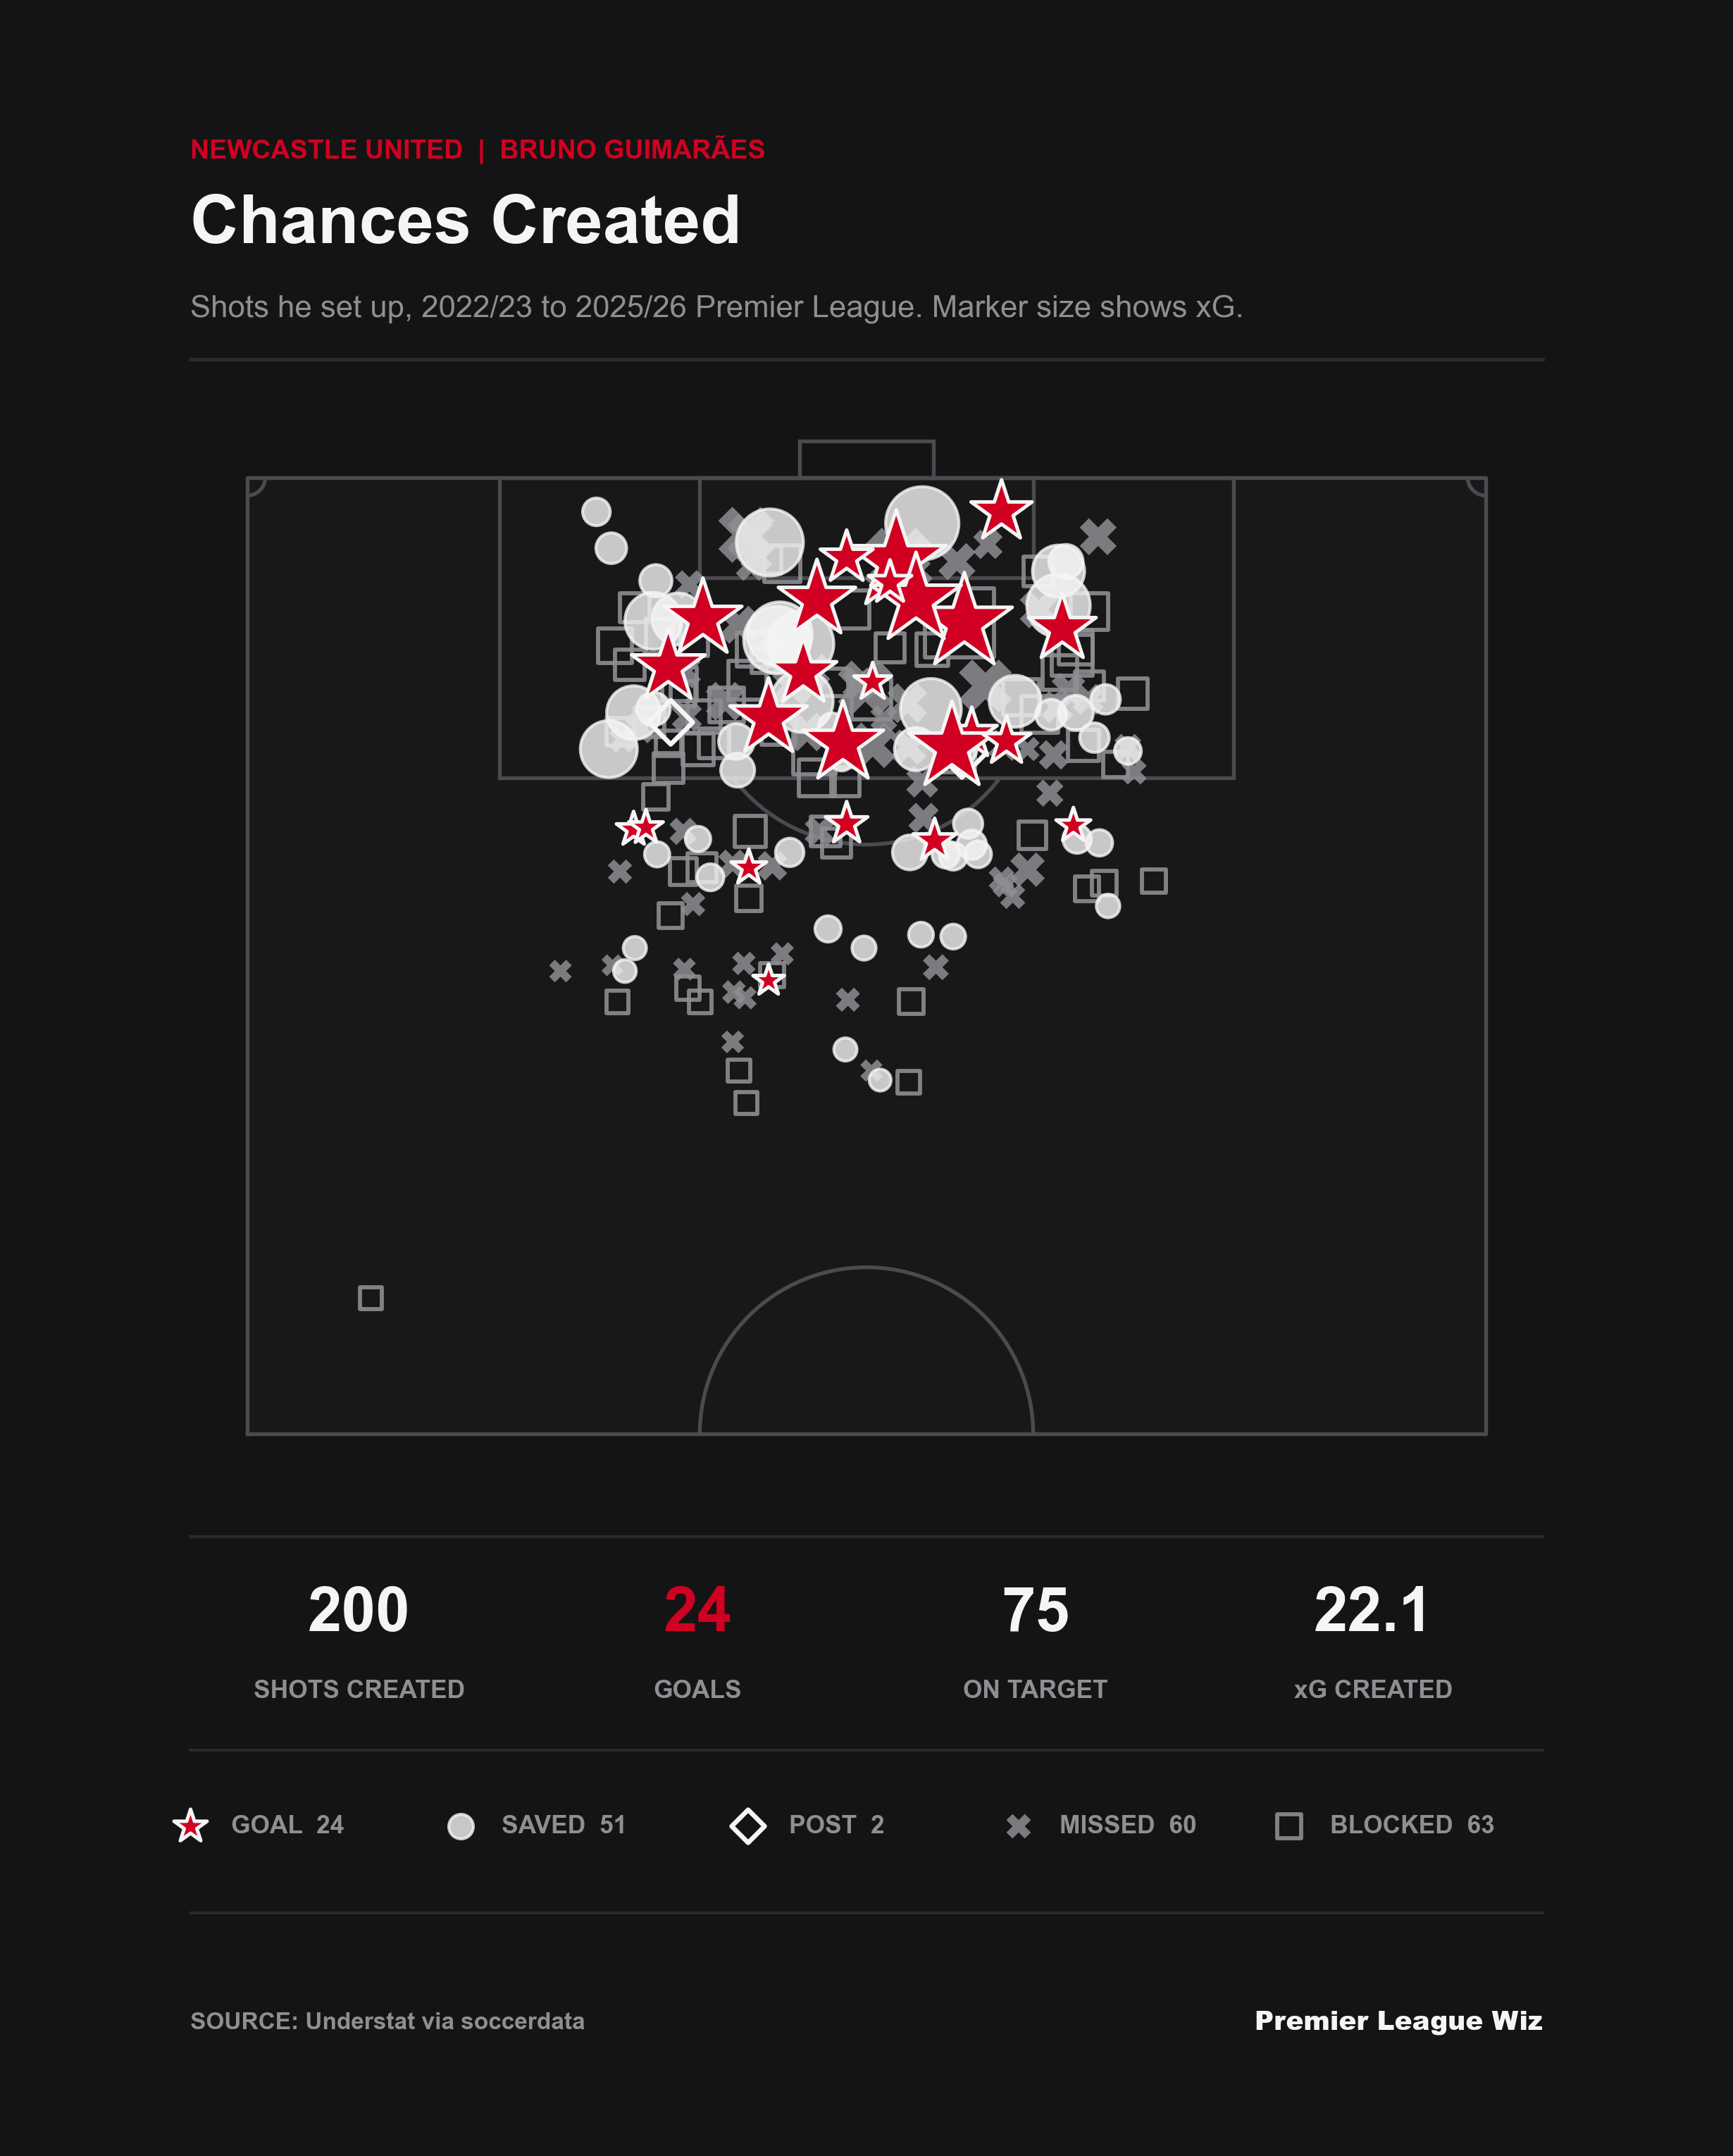

In [36]:
bg37 = df[df["assist_player"] == "Bruno Guimarães"]
plot_shot_map(bg37, player="Bruno Guimarães")

In [25]:
df[df['team'] == 'Newcastle']


,league,season,game,team,player,league_id,season_id,game_id,date,shot_id,...,player_id,assist_player_id,assist_player,xg,location_x,location_y,minute,body_part,situation,result


In [34]:
df[df['team'] == 'Newcastle United']

,league,season,game,team,player,league_id,season_id,game_id,date,shot_id,...,player_id,assist_player_id,assist_player,xg,location_x,location_y,minute,body_part,situation,result
114,ENG-Premier League,2223,2022-08-06 Newcastle United-Nottingham Forest,Newcastle United,Allan Saint-Maximin,1,2022,18206,2022-08-06 14:00:00,479301,...,101,539460.0,Miguel Almirón,0.150258,0.948,0.473,26,NaN,Open Play,Blocked Shot
115,ENG-Premier League,2223,2022-08-06 Newcastle United-Nottingham Forest,Newcastle United,Allan Saint-Maximin,1,2022,18206,2022-08-06 14:00:00,479307,...,101,539457.0,Joelinton,0.037281,0.814,0.621,36,Right Foot,Open Play,Saved Shot
116,ENG-Premier League,2223,2022-08-06 Newcastle United-Nottingham Forest,Newcastle United,Allan Saint-Maximin,1,2022,18206,2022-08-06 14:00:00,479312,...,101,539460.0,Miguel Almirón,0.115628,0.933,0.614,56,Right Foot,Open Play,Blocked Shot
117,ENG-Premier League,2223,2022-08-06 Newcastle United-Nottingham Forest,Newcastle United,Allan Saint-Maximin,1,2022,18206,2022-08-06 14:00:00,479319,...,101,539467.0,Ryan Fraser,0.055230,0.851,0.707,83,Right Foot,Open Play,Missed Shot
118,ENG-Premier League,2223,2022-08-06 Newcastle United-Nottingham Forest,Newcastle United,Bruno Guimarães,1,2022,18206,2022-08-06 14:00:00,479302,...,8327,539456.0,Matt Targett,0.017333,0.743,0.473,26,Right Foot,Open Play,Missed Shot
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40773,ENG-Premier League,2627,2026-09-19 Newcastle United-Hull,Newcastle United,Lewis Hall,1,2026,31223,2026-09-19 14:00:00,695913,...,10216,802983.0,Jacob Murphy,0.124691,0.971,0.603,32,Right Foot,Open Play,Missed Shot
40774,ENG-Premier League,2627,2026-09-19 Newcastle United-Hull,Newcastle United,Matias Fernandez-Pardo,1,2026,31223,2026-09-19 14:00:00,695919,...,13051,802982.0,Sean Steur,0.052412,0.861,0.271,54,Right Foot,Open Play,Blocked Shot
40775,ENG-Premier League,2627,2026-09-19 Newcastle United-Hull,Newcastle United,Sven Botman,1,2026,31223,2026-09-19 14:00:00,695917,...,8635,802980.0,Lewis Hall,0.034860,0.909,0.442,51,NaN,Set Piece,Saved Shot
40776,ENG-Premier League,2627,2026-09-19 Newcastle United-Hull,Newcastle United,Yoane Wissa,1,2026,31223,2026-09-19 14:00:00,695914,...,5786,NaN,NaN,0.761169,0.885,0.500,46,Right Foot,NaN,Saved Shot
